# Data exploration

## Import necessary libraries

In [1]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import FeatureUnion
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
from matplotlib.colors import ListedColormap


# helper validation
from sklearn.utils.validation import check_is_fitted

import os
import tarfile
from six.moves import urllib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

### Load Data

In [2]:
path1 = "../Data/Processed/wind_persistance_polar.csv"

def load_data(path):
    data = pd.read_csv(path)
    return data

wind_persistance_polar = load_data(path1)
wind_persistance_polar['TIMESTAMP'] = pd.to_datetime(wind_persistance_polar['TIMESTAMP'])

wind_persistance_polar.head()

,TIMESTAMP,POWER,wind_speed_10m,wind_direction_10m,wind_speed_100m,wind_direction_100m
0,2015-01-01 01:00:00,0.666693,7.153548,29.256924,10.849239,26.170089
1,2015-01-01 02:00:00,0.666693,6.936405,35.849781,10.616231,32.586965
2,2015-01-01 03:00:00,0.666693,7.738767,39.221140,11.812319,36.287312
3,2015-01-01 04:00:00,0.666693,8.406860,34.742594,12.596636,32.424540
4,2015-01-01 05:00:00,0.666693,8.466898,34.798897,12.647559,32.212561


### Power vs Wind Speed

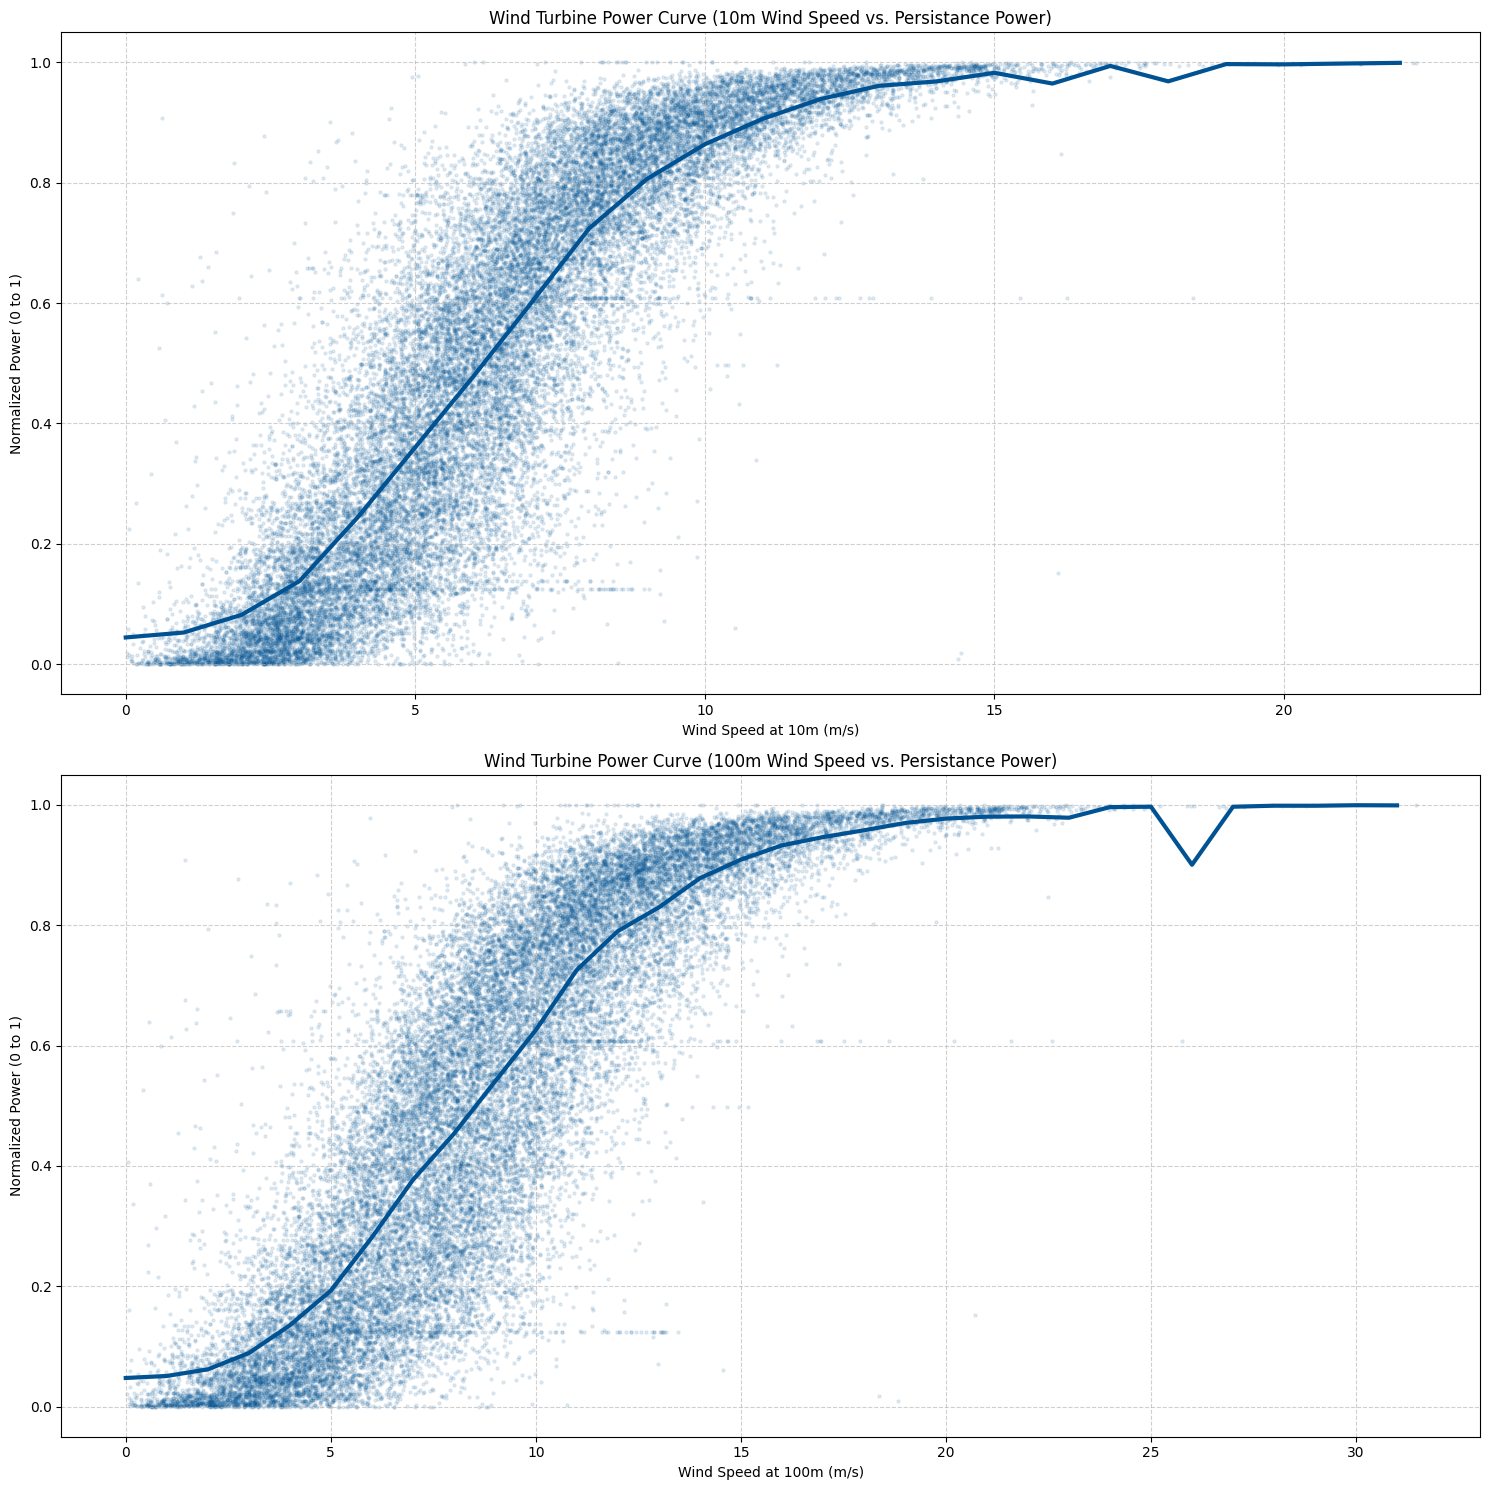

In [3]:
avg_power_10m = wind_persistance_polar.groupby(
    wind_persistance_polar['wind_speed_10m'].round()
)['POWER'].mean()

avg_power_100m = wind_persistance_polar.groupby(
    wind_persistance_polar['wind_speed_100m'].round()
)['POWER'].mean()

plt.figure(figsize=(15, 15))

# Plot 1: persistance data at 10m
plt.subplot(2, 1, 1)
plt.scatter(
    wind_persistance_polar['wind_speed_10m'],
    wind_persistance_polar['POWER'],
    alpha=0.1,   
    s=5,
    color='#005293'
)
plt.plot(
    avg_power_10m.index,
    avg_power_10m.values,
    color='#005293',
    linewidth=3,
    label='Average Power (1 m/s bins)'
)

plt.title('Wind Turbine Power Curve (10m Wind Speed vs. Persistance Power)')
plt.xlabel('Wind Speed at 10m (m/s)')
plt.ylabel('Normalized Power (0 to 1)')
plt.grid(True, linestyle='--', alpha=0.6)

# Plot 2: persistance data at 100m
plt.subplot(2, 1, 2)
plt.scatter(
    wind_persistance_polar['wind_speed_100m'],
    wind_persistance_polar['POWER'],
    alpha=0.1,   
    s=5,
    color='#005293'
)
plt.plot(
    avg_power_100m.index,
    avg_power_100m.values,
    color='#005293',
    linewidth=3,
    label='Average Power (1 m/s bins)'
)

plt.title('Wind Turbine Power Curve (100m Wind Speed vs. Persistance Power)')
plt.xlabel('Wind Speed at 100m (m/s)')
plt.ylabel('Normalized Power (0 to 1)')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('../Data/Plots/average_power_curve.png', dpi=300) # dpi=300 increases the resolution
plt.show()

**Scatter Plot Analysis**<br><br>

All plots show a similar **"S" shaped power curve**. <br>
**Cut-in Speed** (wind speed at which power rises above 0) and **Rated Speed** (wind speed at which power first hits max) can be estimated. <br>
No **Cut-out Speed** (wind speed at which power drops back to 0) is visible. <br>
The difference between the 3 differently interpolated power data is not visible, as only 2% of the data was missing. <br>
Between to data at 10m and 100m seems to be shifted by 3-5 m/s, but nothing unusual. <br>
Generally I (Jonas) would focus on the wind speeds at 100m as thats generally closer to the hub heigt of the turbine, maybe we can explore later if it makes a difference, when dropping the 10m speeds.

### Correlation Heatmap

Quantitative overview of the linear relationships between all the variable. 
<br>
Here the persistance data is chosen.

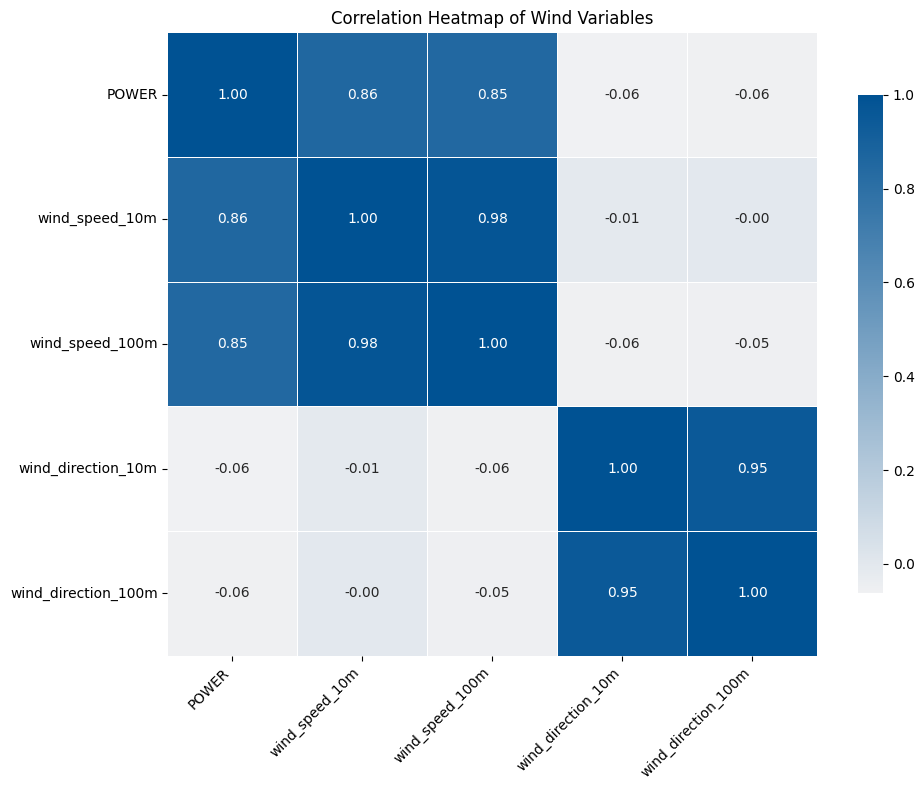

In [4]:
# 1. Define the columns you want to correlate
columns_to_correlate = [
    'POWER',
    'wind_speed_10m',
    'wind_speed_100m',
    'wind_direction_10m',
    'wind_direction_100m'
]

# 2. Calculate the correlation matrix
corr_matrix = wind_persistance_polar[columns_to_correlate].corr()

# 3. Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,      # Show the correlation values on the heatmap
    fmt='.2f',       # Format the values to 2 decimal places
    cmap=sns.light_palette("#005293", as_cmap=True),     # Use a custom color map
    linewidths=.5,   # Add thin lines between cells
    cbar_kws={"shrink": .8} # Make the color bar a bit smaller
)

# Add labels and a title for clarity
plt.title('Correlation Heatmap of Wind Variables')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Ensure the plot layout is tight
plt.tight_layout()

# Save the heatmap
plt.savefig('../Data/Plots/correlation_heatmap.png', dpi=300) # dpi=300 increases the resolution

# Display the plot
plt.show()

**Correlation Heatmap Analysis**

Very positive correlation between POWER and wind_speed (similar at 10m and 100m). <br>
Correlation between wind_speed_10m and wind_speed_100m almost 100 -> doesn't really matter what we use. <br>
Very low correlation between POWER and wind_direction -> no linear relationship between wind_direction and POWER. <br>
Correlation between wind_direction_10m and wind_direction_100m almost 100 -> wind direction consistent between the altitudes. <br><br>

=> wind speed ist the strongest predicter for POWER. No matter 10m or 100m.


### Wind Direction Polar Plot

Confirm that there is no correlation between the wind direction and power, by plotting a polar plot showing the power for each wind direction.<br> 
Here the persistance data at 100m is used. 
<br>
A second plot is added showing in what areas of the density is the highest.

C:\Users\Dell\AppData\Local\Temp\ipykernel_27300\3612597349.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'])


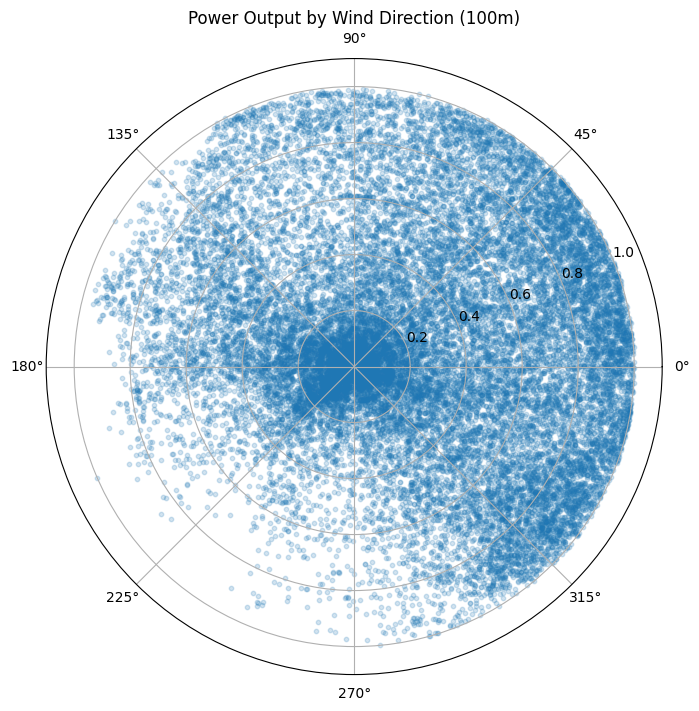

In [5]:
# 1. Convert wind direction from degrees to radians for plotting
# Matplotlib's polar plot expects angles in radians
theta = wind_persistance_polar['wind_direction_100m'] * np.pi / 180.0
radius = wind_persistance_polar['POWER']

# 2. Create the polar plot
plt.figure(figsize=(10, 8))
# Use subplot(projection='polar')
ax = plt.subplot(111, projection='polar')

# 3. Create the scatter plot
# The angle (theta) is the first argument, radius (power) is the second
ax.scatter(
    theta,
    radius,
    alpha=0.2, # Use a very low alpha to see density
    s=10
)

# 4. Configure the plot for wind direction
# ax.set_theta_zero_location('N')  # Set 0 degrees (North) to the top
# ax.set_theta_direction(-1)       # Set angles to go clockwise

# 5. Add a title
plt.title('Power Output by Wind Direction (100m)')

# Set the radial (power) limits
ax.set_rlim(0, 1.1)
ax.set_rlabel_position(22.5) # Move radial labels to not overlap
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'])

# Display the plot
plt.show()

C:\Users\Dell\AppData\Local\Temp\ipykernel_27300\3320406574.py:55: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'])


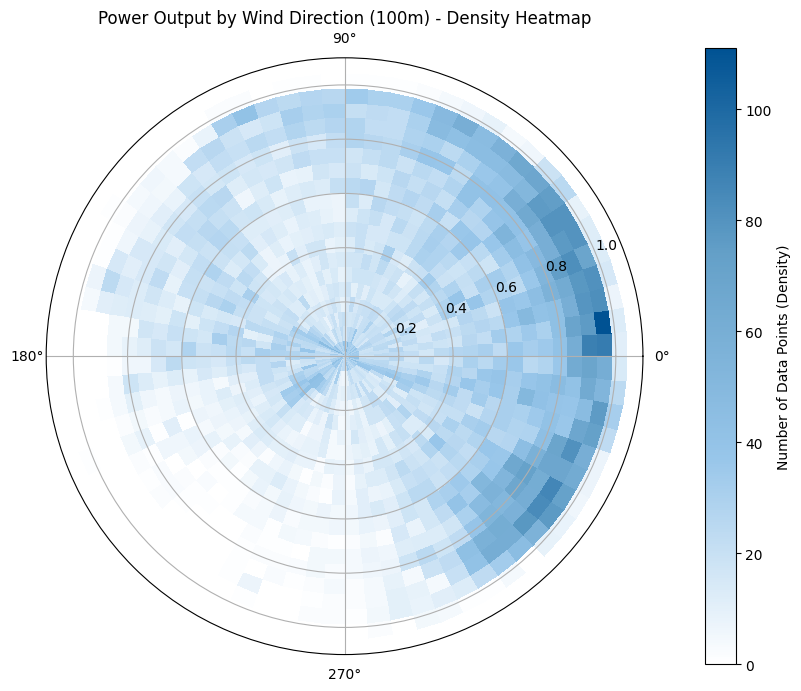

In [6]:
# 1. Convert wind direction from degrees to radians for plotting
# Matplotlib's polar plot expects angles in radians
from matplotlib.colors import LinearSegmentedColormap


theta = wind_persistance_polar['wind_direction_100m'] * np.pi / 180.0
radius = wind_persistance_polar['POWER']

# 2. Create the polar plot
plt.figure(figsize=(10, 8)) # Made figure wider to accommodate the color bar
# Use subplot(projection='polar')
ax = plt.subplot(111, projection='polar')

# 3. Create 2D Histogram for Density ---
# Define the bins
N_theta_bins = 72  # One bin every 5 degrees
N_radius_bins = 20 # Bins for power
theta_bins = np.linspace(0.0, 2 * np.pi, N_theta_bins + 1)
radius_bins = np.linspace(0.0, 1.1, N_radius_bins + 1) # from 0 to max power (1.1)

# Calculate the 2D histogram
# This counts how many points fall into each (theta, radius) bin
density, _, _ = np.histogram2d(theta, radius, bins=(theta_bins, radius_bins))

# Transpose density for pcolormesh
# np.histogram2d bins[0] = x (theta), bins[1] = y (radius)
# pcolormesh expects Z[y, x]
density = density.T

colors = ['#FFFFFF', '#98C6EA', '#64A0C8', '#005293']
custom_cmap = LinearSegmentedColormap.from_list("custom_blue_gradient", colors)

# 4. Plot the density heatmap ---
# We use pcolormesh instead of scatter.
# This colors each bin based on the 'density' (count)
c = ax.pcolormesh(
    theta_bins,
    radius_bins,
    density,
    cmap=custom_cmap,    # Use custom colormap
    shading='auto'  # Use 'auto' or 'flat' to avoid warnings
)

# 5. Add a title
plt.title('Power Output by Wind Direction (100m) - Density Heatmap')

# Set the radial (power) limits
ax.set_rlim(0, 1.1)
# Add labels for the angles (0=E, 90=N, 180=W, 270=S)
ax.set_xticks(np.pi/180. * np.array([0, 90, 180, 270]))
ax.set_xticklabels(['0°', '90°', '180°', '270°'])

# Set radius labels
ax.set_rlabel_position(22.5) # Move radial labels to not overlap
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'])

# 7. --- NEW: Add a color bar ---
# This adds a legend that shows what the colors mean
plt.colorbar(c, ax=ax, label='Number of Data Points (Density)', pad=0.08)

# Save the heatmap
plt.savefig('../Data/Plots/polar_density_heatmap.png', dpi=300) # dpi=300 increases the resolution

# Display the plot
plt.show()

**Wind Direction Analysis**

Both plots show that wind directions to the east are more likely as more dots are located on the right side. <br>
In the left side the maximum relative power of 1.0 is, almost never achieved. The reason for that can be that the wind to the west is never enought to achieve the rated power, but it could also mean that other factors prevent the power to reach 1.0. <br>
This has to be further explored!
 


### Comparing power curves for different wind directions

To be able to confirm that the wind direction doesn't effect the power for example by geografical factors,... the power curves for different wind directions are compared.
<br>
Here the persistance data at 100m is used. 

C:\Users\Dell\AppData\Local\Temp\ipykernel_27300\4139565360.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_power_curves = wind_persistance_polar_test.groupby(


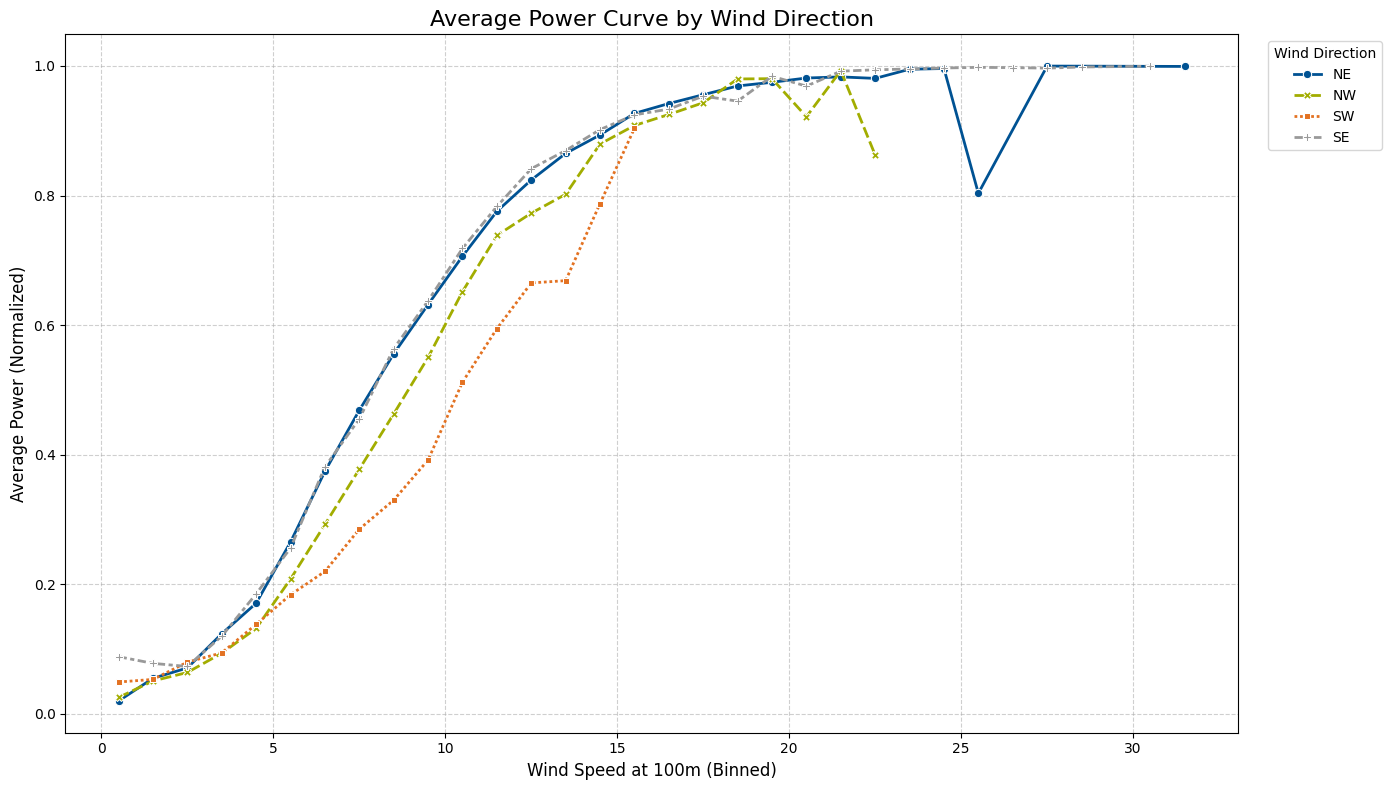

In [7]:
wind_persistance_polar_test = wind_persistance_polar.copy()

# 1. Define the bins for the 4 cardinal directions
# Bins are 90-degrees wide, centered on 0, 90, 180, 270
# Your convention: 0=E, 90=N, 180=W, 270=S
bins = [0, 90, 180, 270, 360]
labels = ['NE', 'NW', 'SW', 'SE']

# 2. Use pd.cut to create the new categorical column
# We have to handle the 0/360 wrap-around for 'East'
wind_persistance_polar_test['wind_direction_bin'] = pd.cut(
    wind_persistance_polar_test['wind_direction_100m'],
    bins=bins,
    labels=labels,
    right=False,
    include_lowest=True
)
# Re-order the categories logically
wind_persistance_polar_test['wind_direction_bin'] = pd.Categorical(wind_persistance_polar_test['wind_direction_bin'], categories=labels, ordered=True)

# 3. NEW: Create wind speed bins and calculate average power
# Create 1 m/s wide bins for wind speed
max_speed = wind_persistance_polar_test['wind_speed_100m'].max()
speed_bins = np.arange(0, max_speed + 1, 1) # e.g., [0, 1, 2, ..., 25]
wind_persistance_polar_test['wind_speed_bin'] = pd.cut(
    wind_persistance_polar_test['wind_speed_100m'],
    bins=speed_bins,
    right=False,
    include_lowest=True
)

# Group by direction and speed bins, then calculate mean power
avg_power_curves = wind_persistance_polar_test.groupby(
    ['wind_direction_bin', 'wind_speed_bin']
)['POWER'].mean().reset_index()

# Get the center of each wind speed bin for plotting
avg_power_curves['wind_speed_center'] = avg_power_curves['wind_speed_bin'].apply(lambda b: b.mid)

custom_palette = ['#005293', '#A2AD00', '#E37222', '#999999']

# 4. Create the line plot
plt.figure(figsize=(14, 8))
sns.lineplot(
    data=avg_power_curves,
    x='wind_speed_center',
    y='POWER',
    hue='wind_direction_bin',   # Color by direction
    style='wind_direction_bin', # Use different line styles
    hue_order=labels,
    palette=custom_palette,
    markers=True,         # Add markers at each data point
    dashes=True,
    lw=2                  # Line width
)

# 5. Clean up the plot
plt.title('Average Power Curve by Wind Direction', fontsize=16)
plt.xlabel('Wind Speed at 100m (Binned)', fontsize=12)
plt.ylabel('Average Power (Normalized)', fontsize=12)
plt.legend(title='Wind Direction', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Save the plot
plt.savefig('../Data/Plots/average_power_curve_by_direction.png', dpi=300) # dpi=300 increases the resolution

# Display the plot
plt.show()

**Power Curve Comparison Analysis**

Looking at the average power curves for the four sectors, it can definitely be seen that wind to east behaves similar, but wind to west especially SW have a lower power curve. This mean that for the same wind speed the average power is lower than for other directions. The maximum power of 1.0 is actually never reached for directions to the west. <br>
=> As a result it is crucial to keep the direction data as they impact the power output. 

### Intra-day exploration

After finding out spatial patterns, lets check out temporal patterns. Here we start with indra-day, looking for a 24-hour pattern.

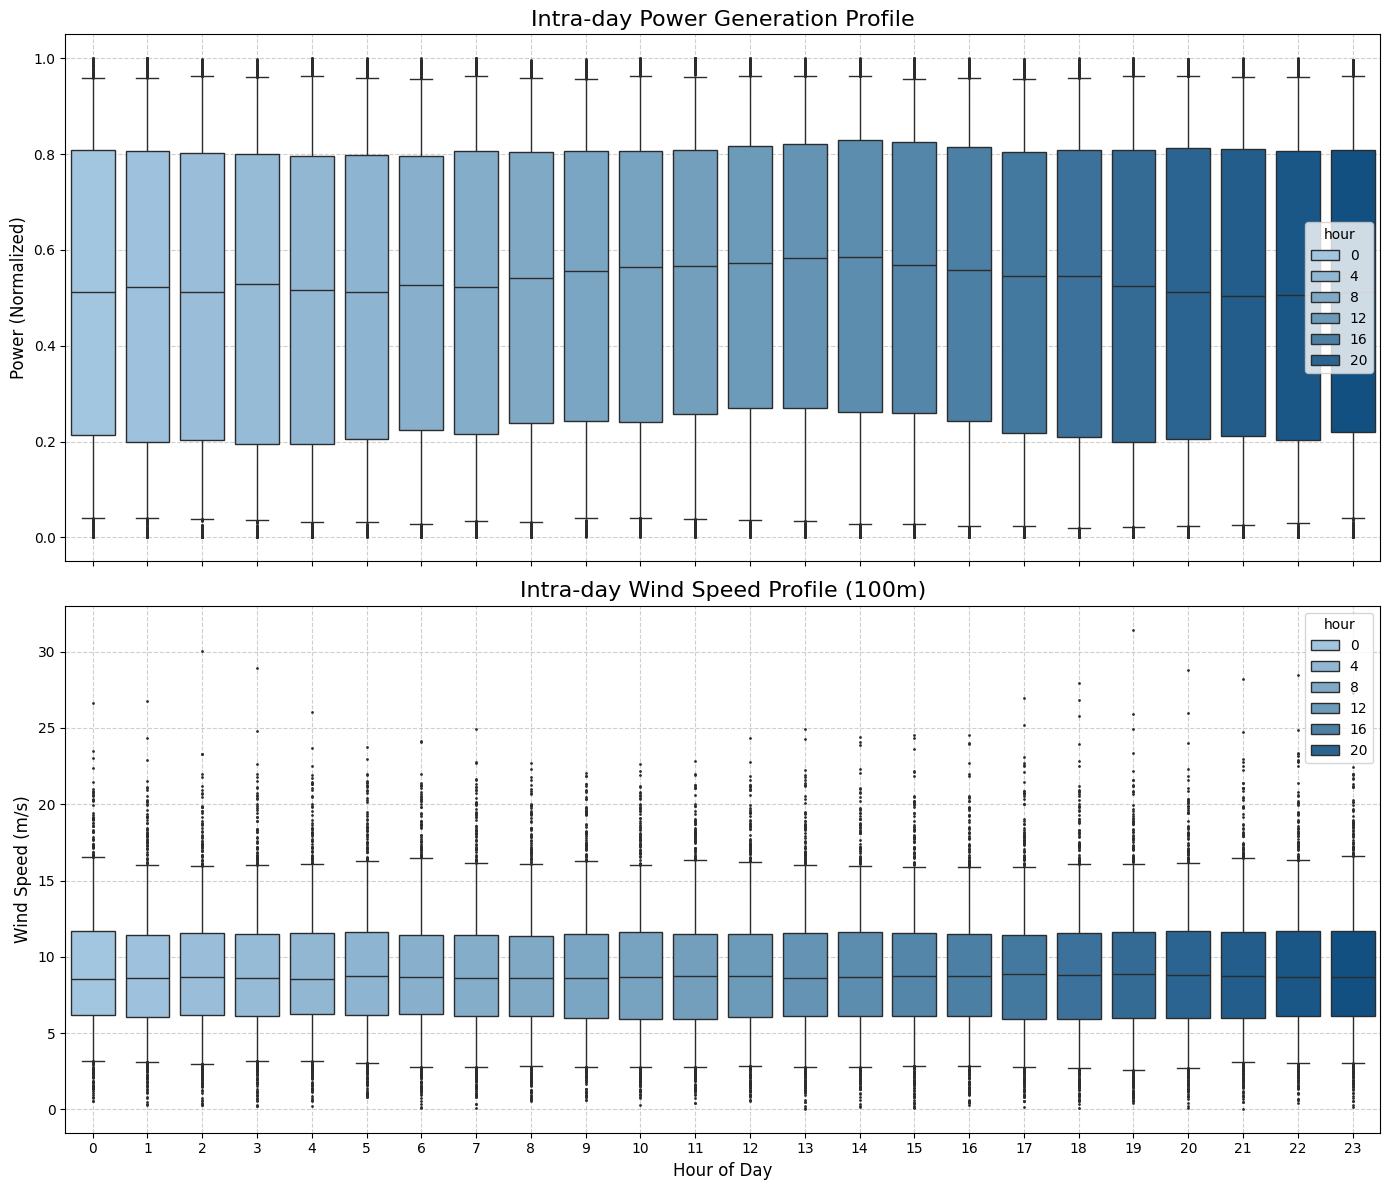

In [8]:
# 1. Create 'hour' column
wind_persistance_polar_test = wind_persistance_polar.copy()
wind_persistance_polar_test['hour'] = wind_persistance_polar_test['TIMESTAMP'].dt.hour

# 2. Create the two-panel figure
# We share the X-axis (hour) for direct comparison
fig, (ax1, ax2) = plt.subplots(
    nrows=2,         # 2 plots, stacked vertically
    ncols=1,
    figsize=(14, 12),
    sharex=True      # This links the x-axes
)

colors = [ '#98C6EA', '#64A0C8', '#005293']
custom_cmap = LinearSegmentedColormap.from_list("custom_blue_gradient", colors)

# 3. Plot 1: Power vs. Hour
sns.boxplot(
    data=wind_persistance_polar_test,
    x='hour',
    hue='hour',
    y='POWER',
    ax=ax1,
    palette=custom_cmap,
    fliersize=1, # Make outlier markers smaller
    whis=[5, 95] # Show 5th and 95th percentiles
)
ax1.set_title('Intra-day Power Generation Profile', fontsize=16)
ax1.set_ylabel('Power (Normalized)', fontsize=12)
ax1.set_xlabel('') # Remove x-label from top plot
ax1.grid(True, linestyle='--', alpha=0.6)

# 4. Plot 2: Wind Speed vs. Hour
sns.boxplot(
    data=wind_persistance_polar_test,
    x='hour',
    hue='hour',
    y='wind_speed_100m',
    ax=ax2,
    palette=custom_cmap,
    fliersize=1,
    whis=[5, 95]
)
ax2.set_title('Intra-day Wind Speed Profile (100m)', fontsize=16)
ax2.set_ylabel('Wind Speed (m/s)', fontsize=12)
ax2.set_xlabel('Hour of Day', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)

# 5. Clean up and display
plt.tight_layout()

# Save the plot
plt.savefig('../Data/Plots/intra_day_profiles.png', dpi=300) # dpi=300 increases the resolution

plt.show()

Interestingly there seems to be no intradray pattern for the wind speed, but the median of the power generation looks to be a bit higher in the day, than in the night.

### Seasonal exploration

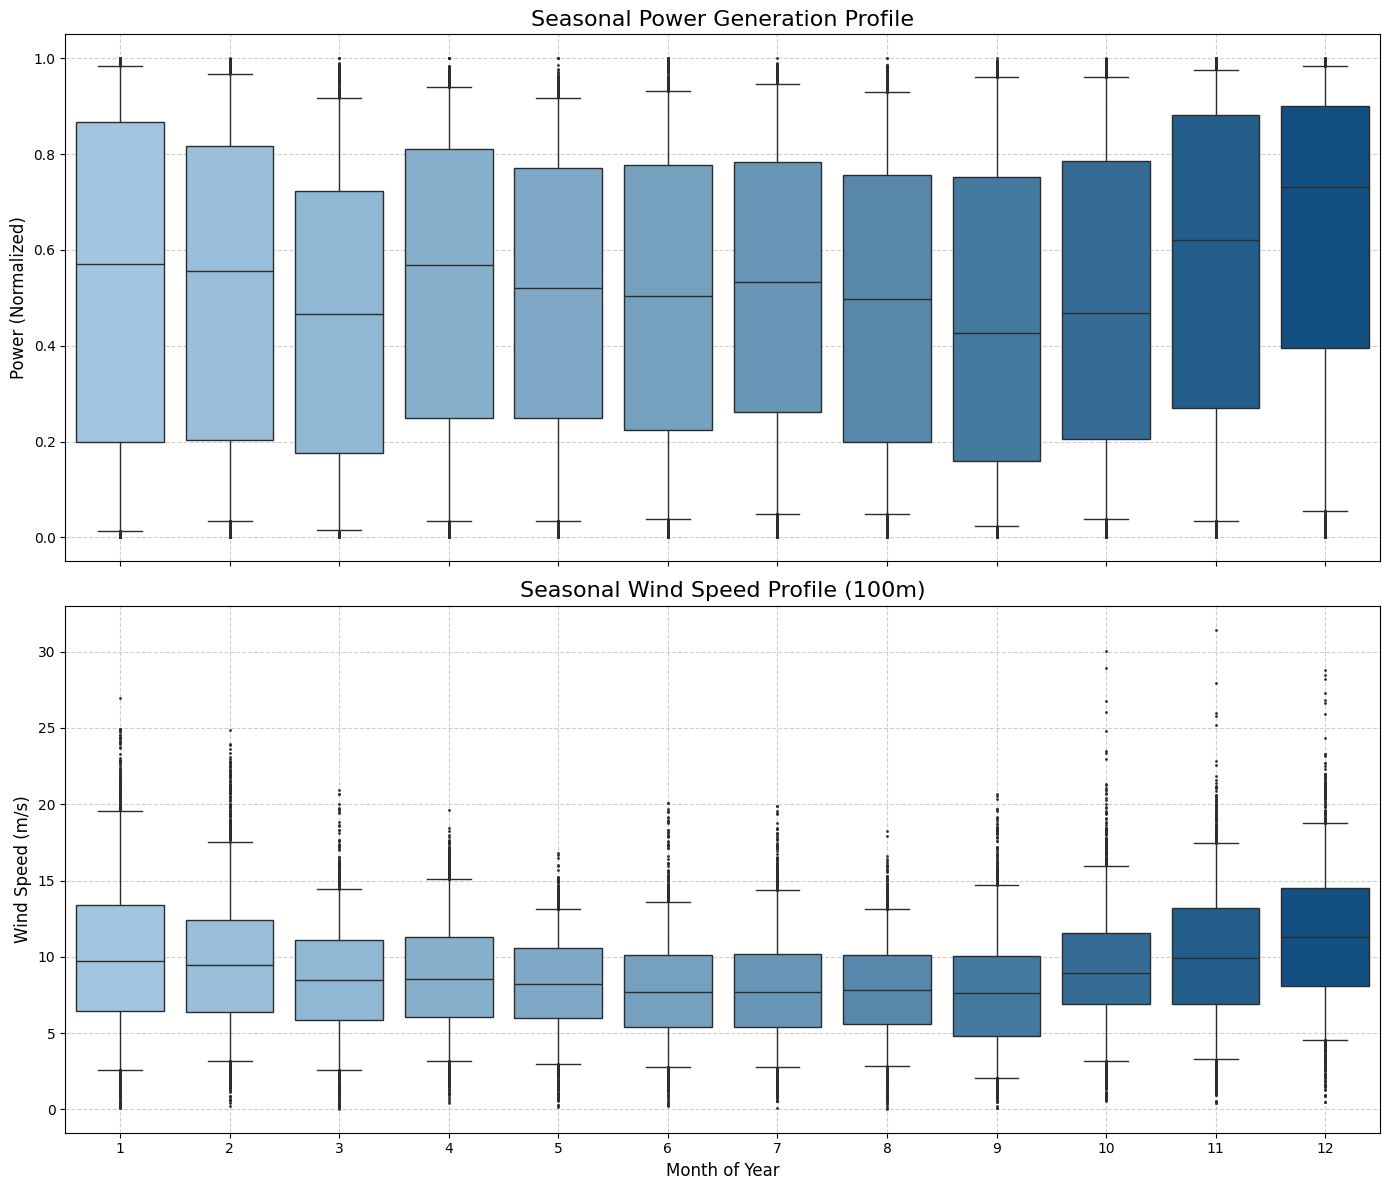

In [9]:
# 1. Create 'month' column
wind_persistance_polar_test = wind_persistance_polar.copy()
wind_persistance_polar_test['month'] = wind_persistance_polar_test['TIMESTAMP'].dt.month

# 2. Create the two-panel figure
fig, (ax1, ax2) = plt.subplots(
    nrows=2,         # 2 plots, stacked vertically
    ncols=1,
    figsize=(14, 12),
    sharex=True      # This links the x-axes
)

colors = [ '#98C6EA', '#64A0C8', '#005293']
custom_cmap = LinearSegmentedColormap.from_list("custom_blue_gradient", colors)

# 3. Plot 1: Power vs. Month
sns.boxplot(
    data=wind_persistance_polar_test,
    x='month',
    y='POWER',
    hue='month',       # Assign 'month' to hue
    ax=ax1,
    palette=custom_cmap,
    legend=False,      # Hide the legend
    fliersize=1,
    whis=[5, 95]
)
ax1.set_title('Seasonal Power Generation Profile', fontsize=16)
ax1.set_ylabel('Power (Normalized)', fontsize=12)
ax1.set_xlabel('')
ax1.grid(True, linestyle='--', alpha=0.6)

# 4. Plot 2: Wind Speed vs. Month
sns.boxplot(
    data=wind_persistance_polar_test,
    x='month',
    y='wind_speed_100m',
    hue='month',       # Assign 'month' to hue
    ax=ax2,
    palette=custom_cmap,
    legend=False,      # Hide the legend
    fliersize=1,
    whis=[5, 95]
)
ax2.set_title('Seasonal Wind Speed Profile (100m)', fontsize=16)
ax2.set_ylabel('Wind Speed (m/s)', fontsize=12)
ax2.set_xlabel('Month of Year', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)

# 5. Clean up and display
plt.tight_layout()

# Save the plot
plt.savefig('../Data/Plots/seasonal_profiles.png', dpi=300) # dpi=300 increases the resolution

plt.show()

Both plots show a strong seasonal "U" shape. Power generation is the highest in the winter months. <br>
Considering the wind speeds, in the summer they are less variable. Whereas in winter the outliers are further away from the boxes. 

## Summary

Jonas:<br>
 - Scatter plot for power curves --> no differences between interpolation methods (only 2% missing data)
 - Correlation heatmap --> strong linear correlation between power and wind speed
 - Polar plot -->  higher power readings for wind to east
 - Power curves for different wind directions --> directions SW and NW produce less power per wind speed
 - Intra-day --> no clear pattern between different hours and power
 - Seasonal --> clear pattern, winter more power, summer less